# H13：同为T14:30，普通量价之外的逐笔信息还有多少增量

## 已执行结果索引

36次新拟合与18组旧模型恢复已完成。下面是传统GBDT在相同T14:30截点的计算结果。
命中率按日期等权，单位为%；增量单位为百分点。普通量价与全部特征均包含相同P日频7列。

| 期限 | 阶段 | P日频7列 | ＋T普通量价32列 | ＋逐笔摘要52列 | 逐笔额外增量 |
| --- | --- | ---: | ---: | ---: | ---: |
| T+1 | 验证27日 | 32.88 | 49.14 | 49.18 | +0.04 |
| T+1 | 评估17日 | 39.89 | 55.13 | 54.89 | -0.24 |
| T+3 | 验证27日 | 22.56 | 32.73 | 30.72 | -2.01 |
| T+3 | 评估17日 | 29.21 | 33.24 | 30.55 | -2.68 |
| T+5 | 验证27日 | 17.70 | 27.17 | 22.80 | -4.37 |
| T+5 | 评估17日 | 25.88 | 30.87 | 28.03 | -2.84 |

六组、三模型及随机期望的[完整表](/home/wsw/app/research-evidence/subscription-intraday-ablation-2026-10-08-8phsjgoc/同时点完整对照_命中率百分比.csv)和[配对差](/home/wsw/app/research-evidence/subscription-intraday-ablation-2026-10-08-8phsjgoc/全部配对差_百分点.csv)保存在证据目录。
第5节有主模型全部六组，第6节给出三个模型的条件增量和区间，第7节为结果图。
研究判断和下一步由[卷宗H13](README.md#h13)维护。普通分钟字段来自同一冻结源；本轮没有验证普通行情套餐的字段覆盖，也没有新增独立市场日期。

这是固定范围的信息消融实验；研究判断由[卷宗H13](README.md#h13)维护。
沿用H12相同的507,397行训练样本、T+1/3/5终点日最高价标签及27/17日历史划分。
主对照是P日日频＋T普通量价32列，与再加成交粒度及tick方向的52列。

普通量价只读取价格、成交量、成交额分钟字段，覆盖5/15/30/60分钟和开盘至14:30累计。
全部52列由原H12的47列追加五个成交量排名构成，其他组是保持相对列顺序的子集。
同时复用日频7列与H12原47列，检查时效信息、额外细节和成交量各自对应的对照。

## 协议、边界与复现

证据目录：`/home/wsw/app/research-evidence/subscription-intraday-ablation-2026-10-08-8phsjgoc`。协议已在新特征和新拟合前冻结。
普通量价字段投影自同一冻结数据，不声称某个普通行情套餐实际提供等价数据；笔数也并非所有市场数据中的L2独有字段。
笔均金额=成交额/笔数，tick方向是价格变动代理。历史存储版本没有真实接收时间；44个评价日已经消费。
入场参考价仍为T日`[14:31,14:36)`VWAP，标签为T+h终点日最高价收益，不是多日累计最高价或可成交收益。

复现须新建空目录，复制`input-manifest.json`列出的全部相对路径文件，以及`runtime-source/`、
`environment/`、`environment.json`、`anchor-source-manifest.json`、`input-manifest.json`、`protocol.json`与`execute_notebook.py`。
把`notebook-before-execution.ipynb`复制为新目录的`intraday_information_ablation.ipynb`，不要复制`runs/`、`models/`等派生结果。
设置`SUBSCRIPTION_ABLATION_EVIDENCE=<新目录>`及`PYTHONPATH=<新目录>/runtime-source`，使用协议绑定的只读隔离环境：

```text
<venv>/bin/python <新目录>/execute_notebook.py <新目录>/intraday_information_ablation.ipynb <新目录>
```

不覆盖本轮证据；全部六组、七项配对差和失败均保留，不因效果更改候选或参数。

In [1]:
from pathlib import Path
from datetime import datetime, date, time
from zoneinfo import ZoneInfo
from dataclasses import asdict
import hashlib
import importlib.metadata
import json
import math
import os
import platform
import time as wall_time
import traceback
import warnings

import joblib
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq
from joblib import Parallel, delayed
from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import roc_auc_score, brier_score_loss
from threadpoolctl import threadpool_limits
from IPython.display import display, Image

import src
from src.training.top_selection import select_top_symbols, evaluate_top_selection
from src.utils.datetime_utils import DateTimeUtils
from src.utils.filesystem import FileSystem
from src.utils.parquet_writer import write_parquet_atomic

evidence = Path(os.environ.get('SUBSCRIPTION_ABLATION_EVIDENCE','/home/wsw/app/research-evidence/subscription-intraday-ablation-2026-10-08-8phsjgoc'))
assert Path(src.__file__).resolve() == (evidence/'runtime-source/src/__init__.py').resolve()
protocol_bytes = (evidence/'protocol.json').read_bytes()
protocol_hash = hashlib.sha256(protocol_bytes).hexdigest()
assert protocol_hash == '6a0b74755dd8a23b8b19d2bf2f5606c9eb424be2f781cf58361a985efad220b1'
protocol = json.loads(protocol_bytes)
manifest = json.loads((evidence/'input-manifest.json').read_text())
assert hashlib.sha256((evidence/'input-manifest.json').read_bytes()).hexdigest() == protocol['input_manifest_sha256']
for entry in manifest:
    with (evidence/entry['path']).open('rb') as stream:
        assert hashlib.file_digest(stream,'sha256').hexdigest() == entry['sha256'], entry['path']
source_manifest = json.loads((evidence/'anchor-source-manifest.json').read_text())
assert hashlib.sha256((evidence/'anchor-source-manifest.json').read_bytes()).hexdigest() == protocol['source_manifest_sha256']
for path, entry in source_manifest.items():
    assert hashlib.sha256((evidence/'runtime-source'/path).read_bytes()).hexdigest() == entry['sha256']
assert hashlib.sha256((evidence/'environment/uv.lock').read_bytes()).hexdigest() == protocol['environment_lock_sha256']
environment = json.loads((evidence/'environment.json').read_text())
assert platform.python_version() == environment['python']
for name,version in environment['packages'].items():
    assert importlib.metadata.version(name) == version
for folder in ['features','predictions','models','runs','figures','joblib-temp']:
    (evidence/folder).mkdir(exist_ok=True)
keys = ['symbol','trade_date','decision_ts_utc']
stage_by_date = {day:stage for stage,days in protocol['stages'].items() for day in days}
required_dates = sorted(set(protocol['common_train_dates']+protocol['prediction_dates']))
print({'input_files':len(manifest),'source_files':len(source_manifest),'minute_days':len(required_dates),'protocol_sha256':protocol_hash})

{'input_files': 923, 'source_files': 169, 'minute_days': 146, 'protocol_sha256': '6a0b74755dd8a23b8b19d2bf2f5606c9eb424be2f781cf58361a985efad220b1'}


## 1. 只依赖普通分钟字段的特征与边界检查

收益是严格首末分钟VWAP之比减一，缺端点保留缺失；振幅为最高/最低减一。
成交额与成交量累计后分别排名；观测分钟数除以窗口交易分钟数，不做排名。
所有排名先在T日可见成交股票域计算，再连接原P日资格池。
短窗口与累计分别沿用H12的Pandas和Arrow浮点聚合，以精确恢复共同20列。
成交量先转decimal128求和并保持精度到排名，合成例子检查超过int64及float64精确范围时的区别。

In [2]:
def build_bar_features(bars, trade_day):
    boundaries = {name:DateTimeUtils.local_time_to_utc_epoch_us(moment,trade_day)
                  for name,moment in [('open',time(9,30)),('morning_end',time(11,30)),('afternoon',time(13)),('cutoff',time(14,30))]}
    timestamps = bars.column('minute_start_ts_utc')
    active = pc.or_(pc.and_(pc.greater_equal(timestamps,boundaries['open']),pc.less(timestamps,boundaries['morning_end'])),
                    pc.and_(pc.greater_equal(timestamps,boundaries['afternoon']),pc.less(timestamps,boundaries['cutoff'])))
    visible = bars.filter(pc.and_(pc.equal(bars.column('phase'),2),active))
    symbols = sorted(pc.unique(visible.column('symbol')).to_pylist())
    output = pd.DataFrame({'symbol':pd.Series(symbols,dtype='string'),'trade_date':trade_day.isoformat(),'decision_ts_utc':boundaries['cutoff']})
    for window,minute_count in [('5m',5),('15m',15),('30m',30),('60m',60),('session',210)]:
        start = boundaries['open'] if window=='session' else boundaries['cutoff']-minute_count*60_000_000
        selected = visible.filter(pc.greater_equal(visible.column('minute_start_ts_utc'),start))
        frame = selected.to_pandas()
        integers = pa.table({'symbol':selected.column('symbol'),'volume':pc.cast(selected.column('volume_sum'),pa.decimal128(38,0))})
        volume = integers.group_by('symbol',use_threads=False).aggregate([('volume','sum')]).to_pandas().set_index('symbol').volume_sum
        if window=='session':
            aggregate = selected.group_by('symbol',use_threads=False).aggregate([
                ('notional_sum','sum'),('high','max'),('low','min'),('minute_start_ts_utc','count_distinct')]).to_pandas().set_index('symbol')
            notional = aggregate.notional_sum_sum
            highest,lowest = aggregate.high_max,aggregate.low_min
            observed = aggregate.minute_start_ts_utc_count_distinct
        else:
            grouped = frame.groupby('symbol',sort=False,observed=True)
            notional = grouped.notional_sum.sum()
            highest,lowest = grouped.high.max(),grouped.low.min()
            observed = grouped.minute_start_ts_utc.nunique()
        first = frame.loc[frame.minute_start_ts_utc.eq(start)].set_index('symbol')
        last = frame.loc[frame.minute_start_ts_utc.eq(boundaries['cutoff']-60_000_000)].set_index('symbol')
        first_vwap = first.notional_sum.astype(float)/first.volume_sum.astype(float)
        last_vwap = last.notional_sum.astype(float)/last.volume_sum.astype(float)
        raw = {'edge_vwap_return':last_vwap/first_vwap-1,'high_low_range':highest/lowest-1,'notional':notional}
        for name,values in raw.items():
            output[f'f_l2_{name}_rank_{window}'] = output.symbol.map(values.where(np.isfinite(values))).rank(method='average',ascending=True,pct=True).to_numpy(dtype=float)
        output[f'f_bar_volume_rank_{window}'] = output.symbol.map(volume).rank(method='average',ascending=True,pct=True).to_numpy(dtype=float)
        output[f'f_l2_observed_minute_ratio_{window}'] = output.symbol.map(observed).fillna(0).to_numpy(dtype=float)/minute_count
    return output

test_day = date(2026,2,3)
test_rows = []
for symbol,moments,extra in [('A',[time(9,30),time(14,25),time(14,29)],1),
                            ('B',[time(9,31),time(14,25),time(14,29)],2),('C',[time(9,30),time(14,26)],0)]:
    for index,moment in enumerate(moments):
        test_rows.append({'symbol':symbol,'trade_date':test_day.isoformat(),
            'minute_start_ts_utc':DateTimeUtils.local_time_to_utc_epoch_us(moment,test_day),'phase':2,
            'open':10.,'high':12.+index,'low':9.,'close':11.,
            'volume_sum':2**62+(extra if moment==time(14,29) else 0),'notional_sum':float(2**62)*(10+index)})
synthetic = pa.Table.from_pylist(test_rows)
assert synthetic.column_names==protocol['bar_input_columns']
test_feature = build_bar_features(synthetic,test_day).set_index('symbol')
assert test_feature.loc['A','f_bar_volume_rank_5m'] == 2/3
assert test_feature.loc['B','f_bar_volume_rank_5m'] == 1
assert test_feature.loc['C','f_bar_volume_rank_5m'] == 1/3
assert test_feature.loc[['B','C'],'f_l2_edge_vwap_return_rank_session'].isna().all()
assert test_feature.loc['C','f_l2_edge_vwap_return_rank_5m']!=test_feature.loc['C','f_l2_edge_vwap_return_rank_5m']
np.testing.assert_array_equal(test_feature.f_l2_observed_minute_ratio_session,[3/210,3/210,2/210])
np.testing.assert_array_equal(test_feature.f_l2_observed_minute_ratio_5m,[2/5,2/5,1/5])
poison = [dict(test_rows[0],symbol='FUTURE_ONLY',phase=phase,
               minute_start_ts_utc=DateTimeUtils.local_time_to_utc_epoch_us(moment,test_day),notional_sum=1e30)
          for moment,phase in [(time(9,25),0),(time(11,30),2),(time(12),2),(time(14,30),2),(time(15),2)]]
poisoned = pa.concat_tables([synthetic,pa.Table.from_pylist(poison,schema=synthetic.schema)])
pd.testing.assert_frame_equal(test_feature,build_bar_features(poisoned,test_day).set_index('symbol'),check_exact=True)
with_detail = synthetic.append_column('trade_count',pa.array([1]*len(synthetic))).append_column('tick_signed_volume_sum',pa.array([7]*len(synthetic)))
changed_detail = with_detail.set_column(with_detail.schema.get_field_index('trade_count'),'trade_count',pa.array([2**62]*len(synthetic)))
changed_detail = changed_detail.set_column(changed_detail.schema.get_field_index('tick_signed_volume_sum'),'tick_signed_volume_sum',pa.array([-2**62]*len(synthetic)))
pd.testing.assert_frame_equal(build_bar_features(with_detail.select(protocol['bar_input_columns']),test_day),
                              build_bar_features(changed_detail.select(protocol['bar_input_columns']),test_day),check_exact=True)
assert select_top_symbols(['a','b','c'],np.array([.9,.8,.7]),top_k=2).tolist()==[0,1]
missing_example = evaluate_top_selection(ranks=np.array([np.nan,.95,.99]),selected=np.array([0,1]))
assert missing_example.selected==2 and missing_example.selected_known==1 and missing_example.hits==1
print('Passed bar-only dependencies, exact volume rank above int64/float64, strict endpoints, coverage, lunch/auction/future exclusion and no replacement of missing labels.')

Passed bar-only dependencies, exact volume rank above int64/float64, strict endpoints, coverage, lunch/auction/future exclusion and no replacement of missing labels.


## 2. 重建146日普通量价并核对H12

全部共有20列必须与冻结H12逐值精确相同。五个新成交量排名另以三个固定日期各两只股票的逐行Python整数求和核对。
这三个日期还比较删除14:30后分钟前后的全部输出，检查截止后数据不会改变候选股票域或排名。
保持原H12四十列的顺序与数值，追加五列量排名；P日频在样本连接阶段加入。

In [3]:
feature_audit = []
shared_bar_columns = [column for column in protocol['ordinary_columns'] if column not in protocol['volume_columns']]
for index,day in enumerate(required_dates):
    pieces = [pq.ParquetFile(evidence/'inputs/current/processed'/f'{exchange}_stock_trade_1m/v1'/f'trade_date={day}'/'data.parquet').read(columns=protocol['bar_input_columns'])
              for exchange in ['sh','sz']]
    bars = pa.concat_tables(pieces)
    assert bars.column_names==protocol['bar_input_columns']
    assert pc.all(pc.equal(bars.column('trade_date'),day)).as_py()
    trade_day = date.fromisoformat(day)
    ordinary = build_bar_features(bars,trade_day)
    original = pd.read_parquet(evidence/'parent-features'/f'{day}.parquet')
    np.testing.assert_array_equal(ordinary[keys].to_numpy(),original[keys].to_numpy())
    np.testing.assert_array_equal(ordinary[shared_bar_columns].to_numpy(dtype=float),original[shared_bar_columns].to_numpy(dtype=float))
    if index in [0,len(required_dates)//2,len(required_dates)-1]:
        cutoff = DateTimeUtils.local_time_to_utc_epoch_us(time(14,30),trade_day)
        prefix = bars.filter(pc.less(bars.column('minute_start_ts_utc'),cutoff))
        pd.testing.assert_frame_equal(ordinary,build_bar_features(prefix,trade_day),check_exact=True)
        bar_rows = prefix.to_pandas()
        for window,minutes in [('5m',5),('15m',15),('30m',30),('60m',60),('session',210)]:
            start = DateTimeUtils.local_time_to_utc_epoch_us(time(9,30),trade_day) if window=='session' else cutoff-minutes*60_000_000
            noon = DateTimeUtils.local_time_to_utc_epoch_us(time(11,30),trade_day)
            afternoon = DateTimeUtils.local_time_to_utc_epoch_us(time(13),trade_day)
            selected = bar_rows.loc[bar_rows.phase.eq(2)&bar_rows.minute_start_ts_utc.ge(start)&
                                    (bar_rows.minute_start_ts_utc.lt(noon)|bar_rows.minute_start_ts_utc.ge(afternoon))]
            exact_totals = selected.groupby('symbol').volume_sum.agg(lambda values:sum(map(int,values))).astype(object)
            for symbol in ordinary.symbol.iloc[:2]:
                if symbol not in exact_totals:
                    assert pd.isna(ordinary.set_index('symbol').loc[symbol,f'f_bar_volume_rank_{window}'])
                    continue
                scalar = sum(int(row.volume_sum) for row in selected.loc[selected.symbol.eq(symbol)].itertuples())
                assert scalar == exact_totals.loc[symbol]
                less = sum(value < scalar for value in exact_totals)
                equal = sum(value == scalar for value in exact_totals)
                expected = (less+(equal+1)/2)/len(exact_totals)
                assert ordinary.set_index('symbol').loc[symbol,f'f_bar_volume_rank_{window}'] == expected
    merged = original.merge(ordinary[keys+protocol['volume_columns']],on=keys,validate='one_to_one',sort=False)
    assert len(merged)==len(original) and not merged.duplicated(keys).any()
    pd.testing.assert_frame_equal(merged[original.columns],original,check_exact=True,check_dtype=False)
    write_parquet_atomic(output_file=evidence/'features'/f'{day}.parquet',table=pa.Table.from_pandas(merged,preserve_index=False))
    feature_audit.append({'trade_date':day,'rows':len(merged),'shared20_exact':True,'volume_columns':5})
    if (index+1)%25==0 or index==len(required_dates)-1:
        print(f'Validated {index+1}/{len(required_dates)} feature days',flush=True)
pd.DataFrame(feature_audit).to_csv(evidence/'feature-audit.csv',index=False)

Validated 25/146 feature days
Validated 50/146 feature days
Validated 75/146 feature days
Validated 100/146 feature days
Validated 125/146 feature days
Validated 146/146 feature days


## 3. 恢复共同训练行及18组锚点

训练行、日期等权和三组已成熟标签保持不变；只改变信息字段。
评价前不剔除未知标签或当日成交缺失股票。daily7与original47直接重放冻结模型，逐条恢复H12分数和时间键。

In [4]:
files = sorted((evidence/'inputs/fixed/features/previous_day_daily_l2/v1').glob('trade_date=*/data.parquet'))
legacy_features = pd.concat([pd.read_parquet(path) for path in files],ignore_index=True)
labels = {h:pd.read_parquet(evidence/f'labels/t{h}.parquet') for h in protocol['horizons']}
for frame in labels.values():
    assert frame[keys].equals(legacy_features[keys]) and not frame.duplicated(keys).any()
fit_table = pd.read_parquet(evidence/'anchor-models/fit-keys.parquet')
mask = legacy_features.trade_date.isin(protocol['common_train_dates'])
for h in protocol['horizons']:
    mask &= labels[h].y_event.notna()
assert legacy_features.loc[mask,keys].reset_index(drop=True).equals(fit_table[keys])
fit_key_hash = hashlib.sha256(pd.util.hash_pandas_object(fit_table[keys],index=True).to_numpy().tobytes()).hexdigest()
assert fit_key_hash==protocol['legacy_fit_key_sha256'] and len(fit_table)==507397
weights = fit_table.weight.to_numpy(copy=True)
counts = fit_table.groupby('trade_date').symbol.transform('size').to_numpy(dtype=float)
expected_weights = 1/counts
expected_weights /= expected_weights.mean()
np.testing.assert_array_equal(weights,expected_weights)
first_decision = DateTimeUtils.local_time_to_utc_epoch_us(time(9),date.fromisoformat(protocol['prediction_dates'][0]))
for h in protocol['horizons']:
    np.testing.assert_array_equal(fit_table[f'y_t{h}'].to_numpy(),labels[h].loc[mask,'y_event'].to_numpy())
    assert labels[h].loc[mask,'label_ready_ts'].lt(first_decision).all()
    changed = labels[h].y_event.copy()
    changed.loc[~legacy_features.trade_date.isin(protocol['common_train_dates'])]=np.nan
    np.testing.assert_array_equal(changed.loc[mask],fit_table[f'y_t{h}'])
current = pd.concat([pd.read_parquet(evidence/'features'/f'{day}.parquet') for day in required_dates],ignore_index=True)
features = legacy_features.loc[legacy_features.trade_date.isin(required_dates)].rename(columns={'decision_ts_utc':'baseline_decision_ts_utc'}).copy()
features['decision_ts_utc'] = features.trade_date.map({day:DateTimeUtils.local_time_to_utc_epoch_us(time(14,30),date.fromisoformat(day)) for day in required_dates})
features = features.merge(current,on=keys,how='left',validate='one_to_one',sort=False,indicator='current_presence')
features['symbol'] = features.symbol.astype(legacy_features.symbol.dtype)
assert features[['symbol','trade_date','baseline_decision_ts_utc']].rename(columns={'baseline_decision_ts_utc':'decision_ts_utc'}).equals(legacy_features.loc[legacy_features.trade_date.isin(required_dates),keys].reset_index(drop=True))
train = fit_table[keys].rename(columns={'decision_ts_utc':'baseline_decision_ts_utc'}).merge(features,on=['symbol','trade_date','baseline_decision_ts_utc'],how='left',validate='one_to_one',sort=False)
evaluation = features.loc[features.trade_date.isin(protocol['prediction_dates'])].reset_index(drop=True)
assert len(train)==507397 and len(evaluation)==219985
new_fit_hash = hashlib.sha256(pd.util.hash_pandas_object(train[keys],index=True).to_numpy().tobytes()).hexdigest()
assert new_fit_hash==protocol['current_fit_key_sha256']
np.testing.assert_array_equal(train[keys+['baseline_decision_ts_utc']].to_numpy(),pd.read_parquet(evidence/'anchor-current-fit-keys.parquet').to_numpy())
prediction_keys = evaluation[keys+['baseline_decision_ts_utc']].copy()
prediction_keys['stage'] = prediction_keys.trade_date.map(stage_by_date)
train_arrays = {group:np.ascontiguousarray(train[columns].fillna(.5).to_numpy(dtype=float)) for group,columns in protocol['features'].items()}
prediction_arrays = {group:np.ascontiguousarray(evaluation[columns].fillna(.5).to_numpy(dtype=float)) for group,columns in protocol['features'].items()}
for group in train_arrays:
    assert np.isfinite(train_arrays[group]).all() and np.isfinite(prediction_arrays[group]).all()
    assert np.min(train_arrays[group])>=0 and np.max(train_arrays[group])<=1
missing = features.groupby('trade_date').agg(pool=('symbol','size'),current_missing=('current_presence',lambda s:int(s.eq('left_only').sum())))
missing.to_csv(evidence/'pool-coverage.csv')
fit_records=[]
for name in protocol['models']:
    for h in protocol['horizons']:
        for group,old_group in [('daily7','daily7'),('original47','original47')]:
            stem = f'{name}-t{h}-{old_group}'
            saved = pd.read_parquet(evidence/'anchor-predictions'/f'{stem}.parquet')
            np.testing.assert_array_equal(saved[keys].to_numpy(),prediction_keys[keys].to_numpy())
            bundle = joblib.load(evidence/'anchor-models'/f'{stem}.joblib')
            with threadpool_limits(limits=1):
                scores = bundle.predict(evaluation[protocol['features'][group]].to_numpy(dtype=float)) if name=='hist_gbdt' and group=='daily7' else bundle['estimator'].predict_proba(prediction_arrays[group])[:,1]
            np.testing.assert_array_equal(scores,saved.prediction.to_numpy())
            output = prediction_keys.copy()
            output['prediction']=scores
            write_parquet_atomic(output_file=evidence/'predictions'/f'{name}-t{h}-{group}.parquet',table=pa.Table.from_pandas(output,preserve_index=False))
            fit_records.append({'model':name,'horizon':h,'group':group,'status':'reused','fit_rows':len(train),'prediction_rows':len(evaluation),'replay_exact':True,'warnings':[]})
write_parquet_atomic(output_file=evidence/'fit-keys.parquet',table=pa.Table.from_pandas(train[keys+['baseline_decision_ts_utc']],preserve_index=False))
print({'training_rows':len(train),'prediction_rows_per_output':len(evaluation),'legacy_fit_hash':fit_key_hash,'new_decision_fit_hash':new_fit_hash,'recovered_anchor_scores':18*len(evaluation),'missing_current_stock_days':int(missing.current_missing.sum())})

{'training_rows': 507397, 'prediction_rows_per_output': 219985, 'legacy_fit_hash': '1e7e8ef798e297f6e0931af4c14c11533dc42d4416834507b5e7f9e5ebc53c04', 'new_decision_fit_hash': '42e379aa3da42ea222bc951249e5bf1f3852a52893235368793f88518dd6a4d6', 'recovered_anchor_scores': 3959730, 'missing_current_stock_days': 235}


## 4. 固定36次新拟合

三个模型、三期限、四个新特征组，全部使用同一训练行。固定参数、seed和12个进程，不调参或评价早停。
先启动耗时较长的GBDT任务，其余进程完成敏感性模型；顺序冻结于协议，与效果无关。
每组保留状态、警告、耗时及错误；全部保存模型重载，逐值恢复219,985条预测。

In [5]:
def fit_intraday_model(name,horizon,group,train_matrix,target,sample_weights,predict_matrix,output_keys,configuration,columns,root_path,legacy_hash,current_hash,protocol_digest):
    directory = root_path/'runs'/f'{name}-t{horizon}-{group}'
    directory.mkdir(exist_ok=False)
    started = wall_time.perf_counter()
    record = {'model':name,'horizon':horizon,'group':group,'status':'running','fit_rows':len(target),
              'legacy_fit_key_sha256':legacy_hash,'decision_fit_key_sha256':current_hash,
              'started_at':datetime.now(ZoneInfo('Asia/Shanghai')).isoformat()}
    FileSystem.write_bytes_atomic(directory/'status.json',json.dumps(record,indent=2).encode())
    try:
        constructor = {'gbdt':GradientBoostingClassifier,'hist_gbdt':HistGradientBoostingClassifier,'logistic':LogisticRegression}[name]
        estimator = constructor(**configuration)
        with threadpool_limits(limits=2 if name=='hist_gbdt' else 1), warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            estimator.fit(train_matrix,target,sample_weight=sample_weights)
        fit_seconds = wall_time.perf_counter()-started
        converged = not any(issubclass(w.category,ConvergenceWarning) for w in caught)
        model_path = root_path/'models'/f'{name}-t{horizon}-{group}.joblib'
        joblib.dump({'estimator':estimator,'columns':columns,'fill_value':.5,'decision_time':'14:30',
                     'legacy_fit_key_sha256':legacy_hash,'decision_fit_key_sha256':current_hash,'protocol_sha256':protocol_digest},model_path)
        with threadpool_limits(limits=1):
            np.testing.assert_array_equal(estimator.classes_,[0,1])
            scores = estimator.predict_proba(predict_matrix)[:,1]
            restored = joblib.load(model_path)
            replay = restored['estimator'].predict_proba(predict_matrix)[:,1]
        np.testing.assert_array_equal(scores,replay)
        assert len(scores)==219985 and np.isfinite(scores).all() and scores.min()>=0 and scores.max()<=1
        output = output_keys.copy()
        output['prediction']=scores
        write_parquet_atomic(output_file=root_path/'predictions'/f'{name}-t{horizon}-{group}.parquet',table=pa.Table.from_pandas(output,preserve_index=False))
        record.update(status='complete' if converged else 'unconverged',fit_seconds=fit_seconds,prediction_rows=len(scores),replay_exact=True,
                      warnings=[{'category':w.category.__name__,'message':str(w.message)} for w in caught],
                      model_sha256=hashlib.sha256(model_path.read_bytes()).hexdigest())
    except Exception as error:
        record.update(status='failed',error_type=type(error).__name__,error=str(error),traceback=traceback.format_exc())
    record['total_seconds']=wall_time.perf_counter()-started
    FileSystem.write_bytes_atomic(directory/'status.json',json.dumps(record,ensure_ascii=False,indent=2).encode())
    return record

tasks = protocol['fit_schedule']
assert len(tasks)==36 and len({tuple(task) for task in tasks})==36
new_records = Parallel(n_jobs=12,temp_folder=evidence/'joblib-temp',max_nbytes='10M')(
    delayed(fit_intraday_model)(name,h,group,train_arrays[group],fit_table[f'y_t{h}'].to_numpy(),weights,prediction_arrays[group],prediction_keys,
                               protocol['models'][name]['params'],protocol['features'][group],evidence,fit_key_hash,new_fit_hash,protocol_hash)
    for name,h,group in tasks)
fit_records.extend(new_records)
(evidence/'fit-records.json').write_text(json.dumps(fit_records,ensure_ascii=False,indent=2)+'\n')
display(pd.DataFrame(fit_records).groupby(['model','status']).size().rename('outputs').reset_index())

,model,status,outputs
0,gbdt,complete,12
1,gbdt,reused,6
2,hist_gbdt,complete,12
3,hist_gbdt,reused,6
4,logistic,complete,12
5,logistic,reused,6


## 5. 命中率、覆盖率及名单独立核验

先按分数降序、股票代码升序固定Top50，再评价已知标签，不补选。均值按日期等权，随机项为同池已知标签事件比例。
用独立排序和显式分子分母复核所有名单，原18组的八项日指标必须精确恢复。
下表命中率单位为%；完整108行同时保存Recall、Lift、AUC、Brier及标签覆盖率。

In [6]:
label_days = {h:{day:group.set_index('symbol') for day,group in frame.groupby('trade_date')} for h,frame in labels.items()}
metric_rows=[]
selection_rows=[]
for record in fit_records:
    name,h,group=record['model'],record['horizon'],record['group']
    if record['status']=='failed':
        continue
    predicted = pd.read_parquet(evidence/'predictions'/f'{name}-t{h}-{group}.parquet')
    assert predicted[keys].equals(prediction_keys[keys])
    for day,frame in predicted.groupby('trade_date',sort=True):
        lab = label_days[h][day].reindex(frame.symbol)
        symbols=frame.symbol.to_numpy(dtype=str)
        scores=frame.prediction.to_numpy(dtype=float)
        chosen=select_top_symbols(symbols,scores,top_k=50)
        independent=np.lexsort((symbols,-scores))[:50]
        np.testing.assert_array_equal(chosen,independent)
        values=asdict(evaluate_top_selection(ranks=lab.y_rank_return.to_numpy(dtype=float),selected=chosen))
        selected=lab.iloc[independent]
        assert values['hits']==int(selected.y_event.eq(1).sum())
        assert values['selected_known']==int(selected.y_event.notna().sum())
        assert values['precision']==selected.y_event.mean()
        assert values['random_precision']==lab.y_event.mean()
        known=lab.y_event.notna().to_numpy()
        metric_rows.append({'model':name,'horizon':h,'group':group,'stage':stage_by_date[day],'trade_date':day,'fit_status':record['status'],**values,
                            'auc':roc_auc_score(lab.y_event.to_numpy()[known],scores[known]),
                            'brier':brier_score_loss(lab.y_event.to_numpy()[known],scores[known])})
        selection_rows.append({'model':name,'horizon':h,'group':group,'stage':stage_by_date[day],'trade_date':day,'symbols':symbols[chosen].tolist()})
metrics=pd.DataFrame(metric_rows)
selections=pd.DataFrame(selection_rows)
write_parquet_atomic(output_file=evidence/'daily-metrics.parquet',table=pa.Table.from_pandas(metrics,preserve_index=False))
write_parquet_atomic(output_file=evidence/'selections.parquet',table=pa.Table.from_pandas(selections,preserve_index=False))
anchor = pd.read_parquet(evidence/'anchor-daily-metrics.parquet')
anchor = anchor.loc[anchor.model.isin(protocol['models']) & anchor.group.isin(['daily7','current47'])].replace({'group':{'current47':'original47'}}).set_index(['model','horizon','group','trade_date']).sort_index()
check = metrics.loc[metrics.group.isin(['daily7','original47'])].set_index(['model','horizon','group','trade_date']).sort_index()
for column in ['precision','hits','selected_known','random_precision','recall','lift','auc','brier']:
    np.testing.assert_array_equal(check[column],anchor[column])
summary=metrics.groupby(['model','horizon','stage','group']).agg(days=('trade_date','size'),precision=('precision','mean'),
    hits=('hits','sum'),known=('selected_known','sum'),coverage=('selection_coverage','mean'),recall=('recall','mean'),
    lift=('lift','mean'),random_precision=('random_precision','mean'),auc=('auc','mean'),brier=('brier','mean')).reset_index()
statuses=pd.DataFrame(fit_records)[['model','horizon','group','status']]
complete_index=pd.MultiIndex.from_product([list(protocol['models']),protocol['horizons'],list(protocol['stages']),list(protocol['features'])],names=['model','horizon','stage','group'])
full_summary=summary.set_index(['model','horizon','stage','group']).reindex(complete_index).reset_index().merge(statuses,on=['model','horizon','group'],validate='many_to_one')
full_summary.to_csv(evidence/'complete-summary.csv',index=False)
display(full_summary.loc[full_summary.model.eq('gbdt')].pivot(index=['stage','group'],columns='horizon',values='precision').mul(100).round(4))

horizon                          1        3        5
stage      group                                    
evaluation activity42      54.8908  31.4982  28.3866
           daily7          39.8872  29.2053  25.8824
           direction42     54.6579  33.0012  30.6339
           full52          54.8932  30.5546  28.0312
           original47      55.6014  30.1945  28.0312
           price_volume32  55.1285  33.2365  30.8715
validation activity42      49.3469  30.8339  23.7067
           daily7          32.8768  22.5627  17.7037
           direction42     49.2910  32.4339  27.0234
           full52          49.1791  30.7235  22.8042
           original47      49.6493  31.4356  23.2774
           price_volume32  49.1398  32.7317  27.1731

## 6. 七项配对差、两阶段门槛和区块敏感性

主比较为full52减price_volume32。另检查普通量价相对昨日、两类细节分别加入、控制另一类后的加入，以及新增成交量相对H12原47列。
固定5日循环区块bootstrap、20,000次，另列10日敏感性与63项校正。
两段通过要求各段均值至少2个百分点且单侧95%下界大于零；这些已消费日期上的判据不是独立确认。
差值及区间展示单位为百分点。独立增加两组的差值不能直接相加，条件差依赖模型与交互。

In [7]:
paired=metrics.pivot(index=['model','horizon','stage','trade_date'],columns='group',values='precision')
paired.to_csv(evidence/'paired-daily.csv')
comparisons=[]
for name in protocol['models']:
    for h in protocol['horizons']:
        for contrast,(treatment,control) in protocol['contrasts'].items():
            records=[r for r in fit_records if r['model']==name and r['horizon']==h and r['group'] in [treatment,control]]
            usable=all(r['status'] in ['complete','reused'] for r in records)
            if any(r['status']=='failed' for r in records):
                continue
            for stage,days in protocol['stages'].items():
                frame=paired.xs((name,h,stage)).reindex(days)
                vector=(frame[treatment]-frame[control]).to_numpy()
                assert np.isfinite(vector).all() and len(vector)==len(days)
                for block in protocol['uncertainty']['block_sessions']:
                    rng=np.random.default_rng(protocol['uncertainty']['seed'])
                    starts=rng.integers(0,len(vector),size=(20000,math.ceil(len(vector)/block)))
                    positions=((starts[...,None]+np.arange(block))%len(vector)).reshape(20000,-1)[:,:len(vector)]
                    draws=vector[positions].mean(axis=1)
                    low,high,one,adjusted=np.quantile(draws,[.025,.975,.05,protocol['uncertainty']['bonferroni_quantile']])
                    comparisons.append({'model':name,'horizon':h,'contrast':contrast,'treatment':treatment,'control':control,'stage':stage,'block_sessions':block,
                                        'mean_difference':vector.mean(),'ci95_lower':low,'ci95_upper':high,'one_sided95_lower':one,'bonferroni_lower':adjusted,
                                        'converged_complete':usable,'nominal_criterion':bool(usable and vector.mean()>=.02 and one>0),
                                        'adjusted_criterion':bool(usable and vector.mean()>=.02 and adjusted>0),'wins':int((vector>0).sum()),'ties':int((vector==0).sum()),'losses':int((vector<0).sum())})
comparison=pd.DataFrame(comparisons)
comparison.to_csv(evidence/'paired-comparison.csv',index=False)
criteria=comparison.groupby(['model','horizon','contrast','block_sessions']).agg(periods=('stage','size'),both_periods_nominal=('nominal_criterion','all'),both_periods_adjusted=('adjusted_criterion','all')).reset_index()
assert criteria.periods.eq(2).all()
criteria.to_csv(evidence/'both-periods-criteria.csv',index=False)
readable=full_summary.pivot(index=['model','horizon','stage'],columns='group',values='precision').reset_index()
random_by_period=metrics.groupby(['horizon','stage']).random_precision.mean()
readable['random']=[random_by_period.loc[(h,s)] for h,s in zip(readable.horizon,readable.stage)]
readable.to_csv(evidence/'comparison-table.csv',index=False)
primary = comparison.loc[comparison.contrast.eq('trade_detail_added') & comparison.block_sessions.eq(5),
                          ['model','horizon','stage','mean_difference','ci95_lower','ci95_upper','bonferroni_lower','wins','ties','losses']].copy()
for column in ['mean_difference','ci95_lower','ci95_upper','bonferroni_lower']:
    primary[column] *= 100
display(primary.round(4))
coverage = metrics.assign(lower_precision=metrics.hits/metrics.selected,
                          upper_precision=(metrics.hits+metrics.selected-metrics.selected_known)/metrics.selected).groupby(['model','horizon','stage','group']).agg(
                              precision=('precision','mean'),lower_precision=('lower_precision','mean'),upper_precision=('upper_precision','mean'),coverage=('selection_coverage','mean')).reset_index()
coverage.to_csv(evidence/'coverage-bounds.csv',index=False)

,model,horizon,stage,mean_difference,ci95_lower,ci95_upper,bonferroni_lower,wins,ties,losses
4,gbdt,1,validation,0.0393,-1.2396,1.2245,-1.9140,9,5,13
6,gbdt,1,evaluation,-0.2353,-1.1765,0.7059,-1.6471,7,5,5
32,gbdt,3,validation,-2.0081,-3.8031,-0.2696,-4.9781,8,3,16
34,gbdt,3,evaluation,-2.6819,-4.9508,-0.2348,-5.9814,3,3,11
60,gbdt,5,validation,-4.3689,-6.7362,-2.0816,-8.1007,3,3,21
62,gbdt,5,evaluation,-2.8403,-4.9748,-0.7059,-6.0168,5,2,10
88,hist_gbdt,1,validation,1.4452,0.1345,2.6772,-0.7075,14,5,8
90,hist_gbdt,1,evaluation,1.5294,0.1176,3.1765,-0.5882,9,3,5
116,hist_gbdt,3,validation,-0.8605,-2.2948,0.4997,-3.1538,9,5,13
118,hist_gbdt,3,evaluation,-1.5414,-4.7419,1.8824,-6.1657,5,2,10


## 7. 全组结果图与逐笔信息的条件增量

第一图比较传统GBDT的全部六组；第二图比较相同T14:30普通量价之上，增加全部逐笔衍生摘要的模型敏感性和名义双侧95%区间。
图中组顺序与协议一致，纵轴分别为命中率百分比和增量百分点，虚线为同池随机期望或2个百分点门槛。

{'protocol_sha256': '6a0b74755dd8a23b8b19d2bf2f5606c9eb424be2f781cf58361a985efad220b1', 'base_commit': '76c25a279685b6961cda69143f542e8ec3936f51', 'legacy_fit_key_sha256': '1e7e8ef798e297f6e0931af4c14c11533dc42d4416834507b5e7f9e5ebc53c04', 'new_decision_fit_key_sha256': '42e379aa3da42ea222bc951249e5bf1f3852a52893235368793f88518dd6a4d6', 'input_files_unchanged': 923, 'source_files_unchanged': 169, 'feature_days': 146, 'anchor_outputs_recovered': 18, 'new_fit_outputs': 36, 'complete_outputs': 54, 'all_complete_converged': True, 'metric_days': 2376, 'predictions': 11879190, 'all_saved_scores_replay_exact': True, 'shared20_features_exact_all_days': True, 'ordinary_inputs_exclude_detail_fields': True, 'new_volume_ranks_independently_checked': True, 'all_selections_independently_recovered': True, 'anchor_metrics_exact': True, 'future_cutoff_checks': True, 'mature_training_labels': True, 'min_group_stage_coverage': 0.9881481481481481, 'research_only': True}


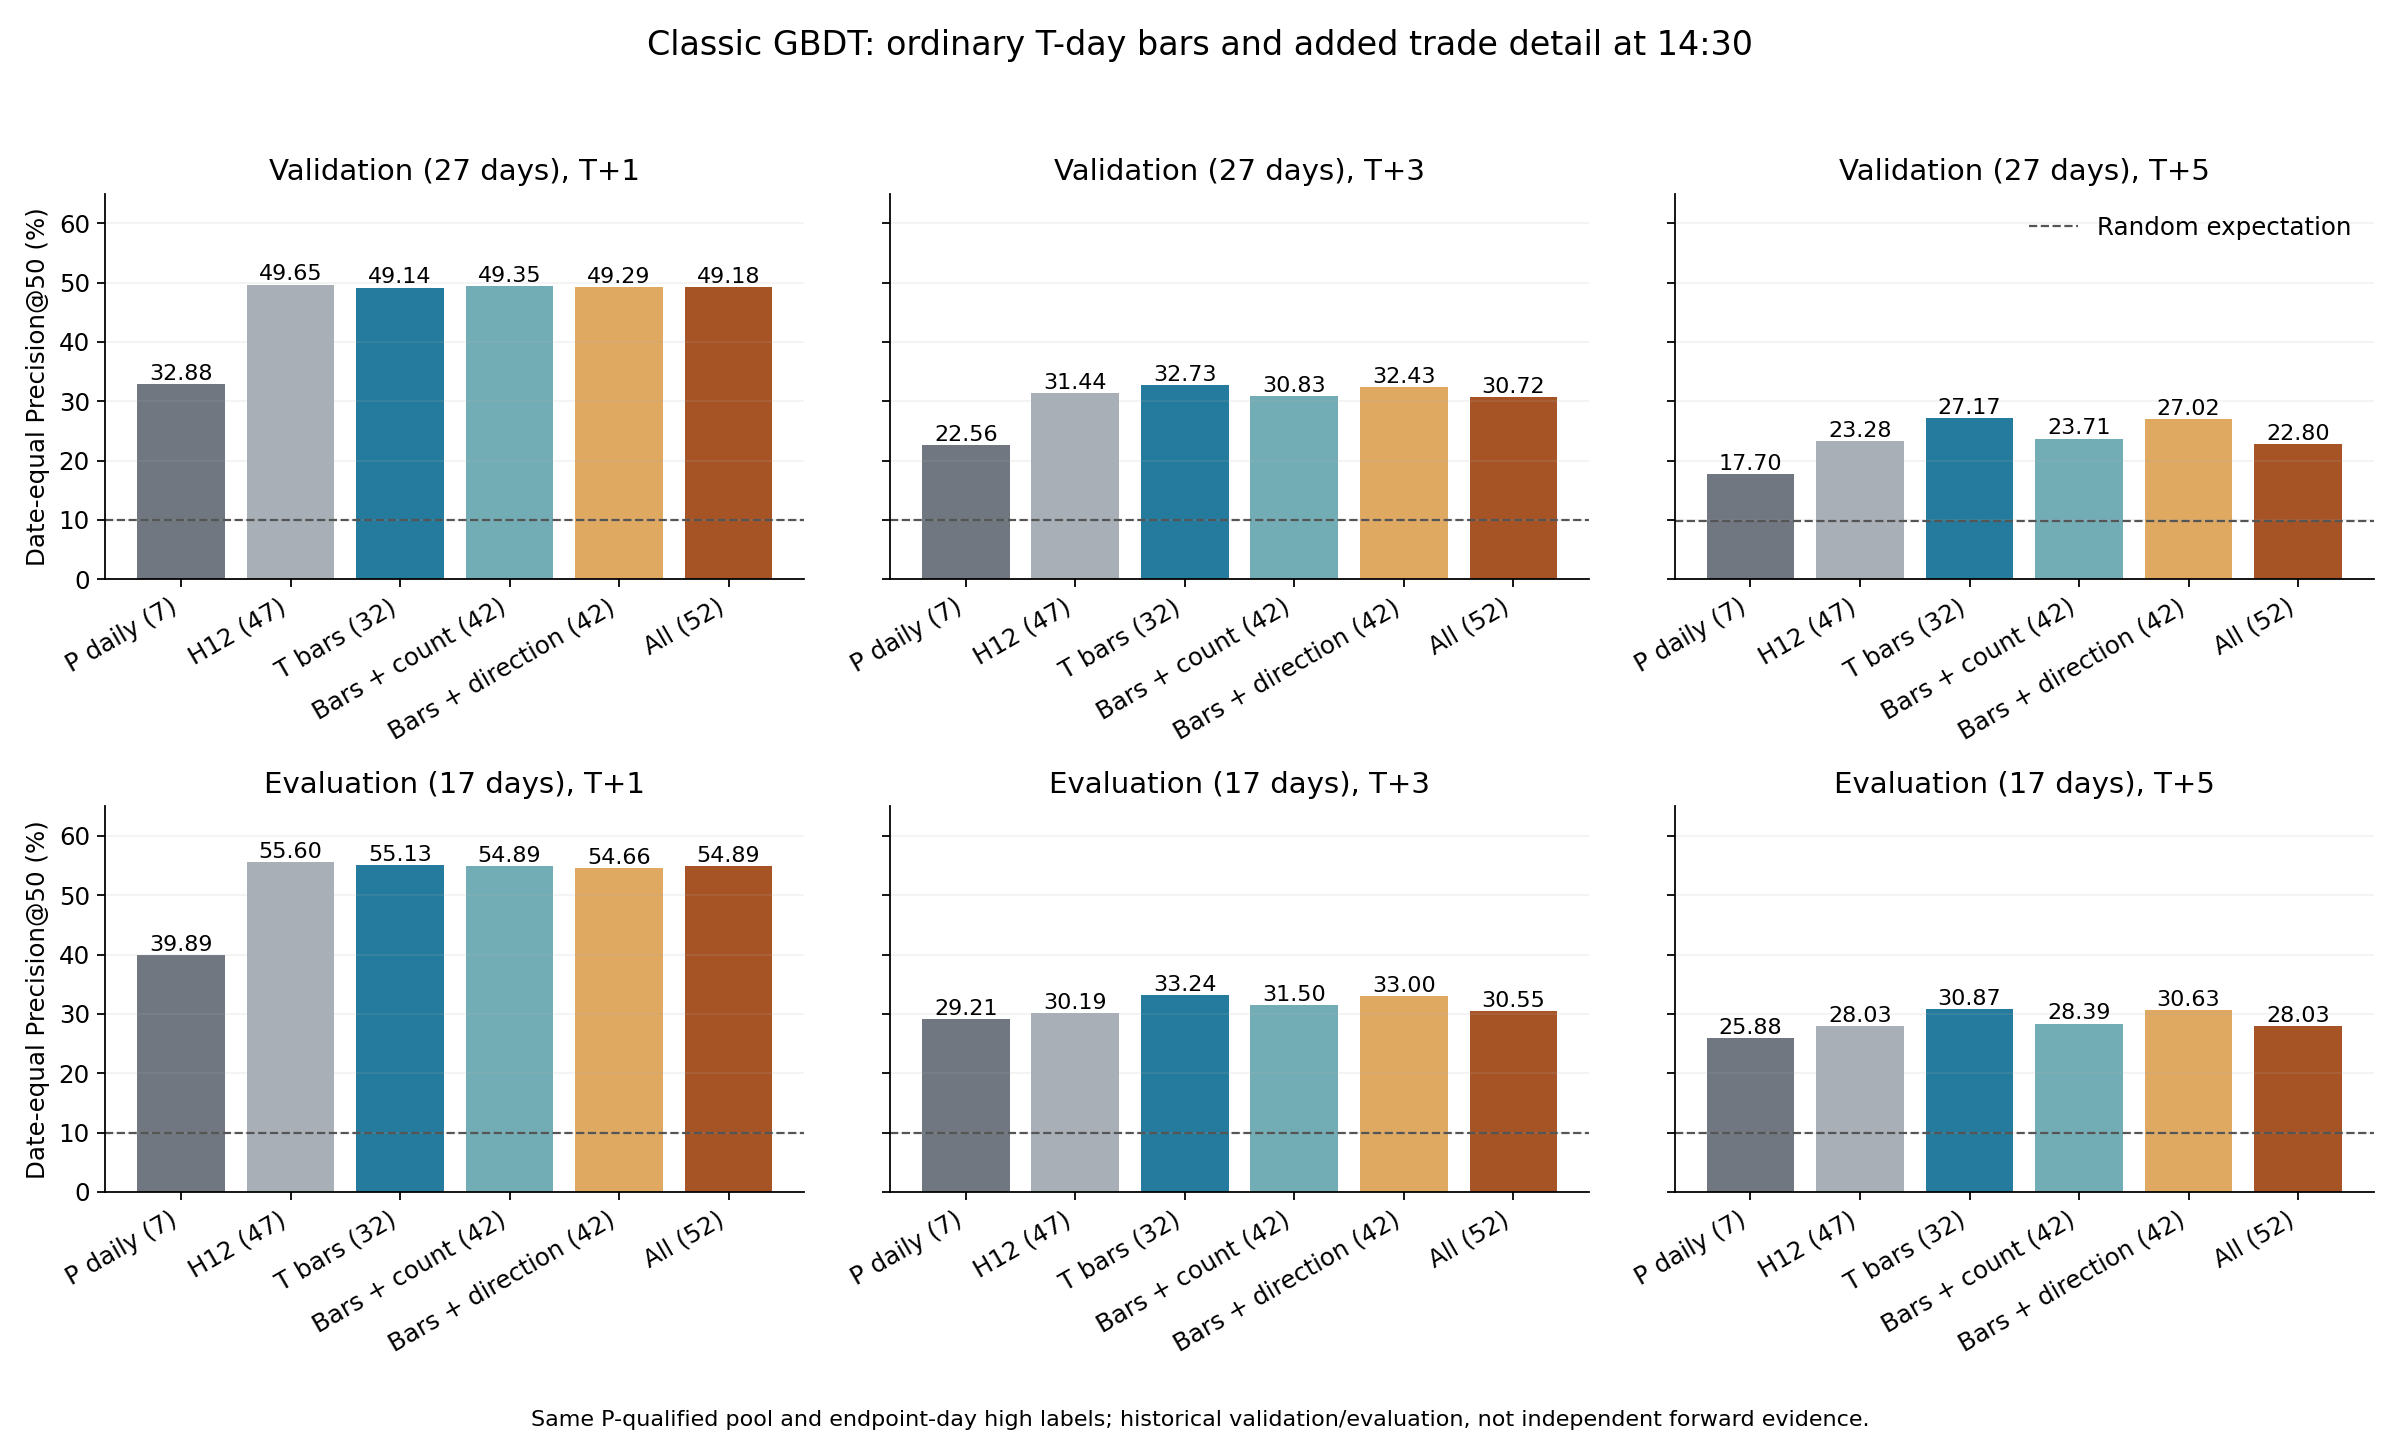

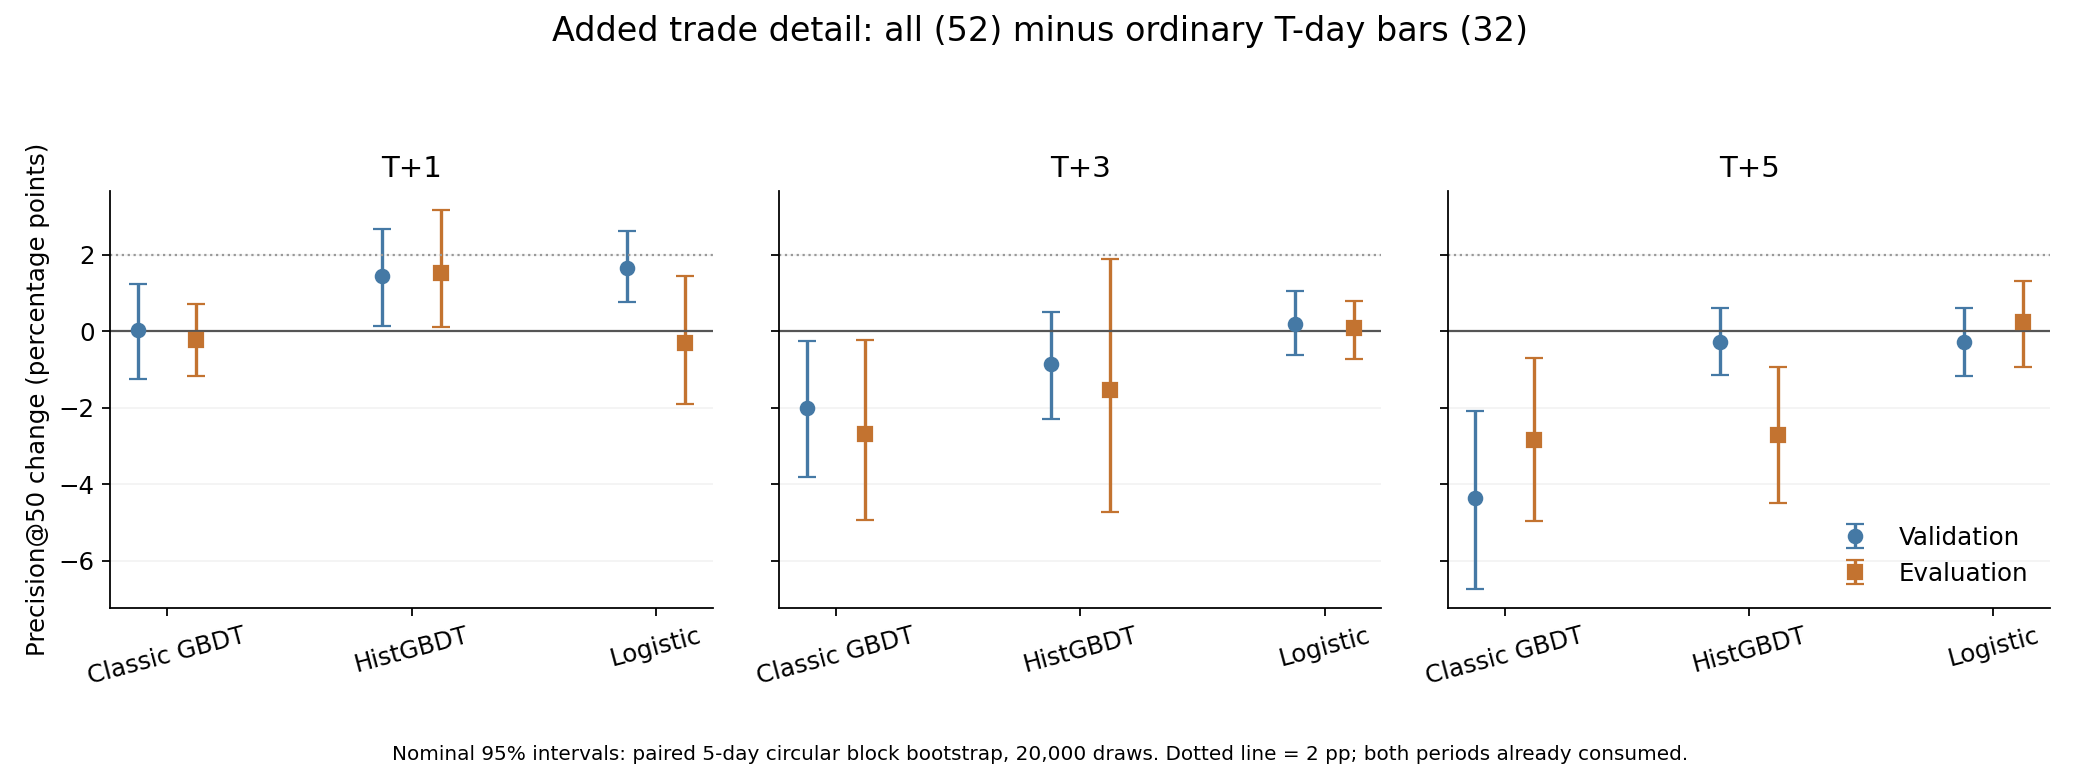

In [8]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':130,'savefig.facecolor':'white'})
group_labels={'daily7':'P daily (7)','original47':'H12 (47)','price_volume32':'T bars (32)','activity42':'Bars + count (42)','direction42':'Bars + direction (42)','full52':'All (52)'}
colors=['#707780','#A8AFB7','#247B9D','#72ADB5','#DFA962','#A65426']
fig,axes=plt.subplots(2,3,figsize=(15,9),sharey=True)
for row,stage in enumerate(protocol['stages']):
    for column,h in enumerate(protocol['horizons']):
        ax=axes[row,column]
        selected=full_summary.loc[full_summary.model.eq('gbdt')&full_summary.stage.eq(stage)&full_summary.horizon.eq(h)].set_index('group').reindex(protocol['features'])
        values=selected.precision.to_numpy()*100
        bars=ax.bar(np.arange(6),values,color=colors)
        ax.axhline(selected.random_precision.iloc[0]*100,color='#555555',ls='--',lw=1,label='Random expectation')
        for bar,value in zip(bars,values):
            if np.isfinite(value):ax.text(bar.get_x()+bar.get_width()/2,value+.7,f'{value:.2f}',ha='center',fontsize=10)
        ax.set_xticks(np.arange(6),list(group_labels.values()),rotation=30,ha='right')
        ax.set_title(f'{stage.title()} ({len(protocol["stages"][stage])} days), T+{h}')
        ax.set_ylim(0,max(55,math.ceil(full_summary.precision.max()*100/10)*10+5))
        ax.grid(axis='y',alpha=.15)
        if column==0:ax.set_ylabel('Date-equal Precision@50 (%)')
        if row==0 and column==2:ax.legend(loc='upper right',frameon=False)
fig.suptitle('Classic GBDT: ordinary T-day bars and added trade detail at 14:30',fontsize=15)
fig.text(.5,.01,'Same P-qualified pool and endpoint-day high labels; historical validation/evaluation, not independent forward evidence.',ha='center',fontsize=10)
fig.tight_layout(rect=[0,.04,1,.95])
fig.savefig(evidence/'figures/gbdt-six-groups.png',dpi=160)
plt.close(fig)
display(Image(filename=str(evidence/'figures/gbdt-six-groups.png')))

fig,axes=plt.subplots(1,3,figsize=(13,4.8),sharey=True)
model_labels={'gbdt':'Classic GBDT','hist_gbdt':'HistGBDT','logistic':'Logistic'}
for ax,h in zip(axes,protocol['horizons']):
    for offset,stage,color,marker in [(-.12,'validation','#4579A5','o'),(.12,'evaluation','#C37330','s')]:
        selected=comparison.loc[comparison.horizon.eq(h)&comparison.contrast.eq('trade_detail_added')&comparison.block_sessions.eq(5)&comparison.stage.eq(stage)].set_index('model').reindex(protocol['models'])
        means=selected.mean_difference.to_numpy()*100
        error=np.vstack([means-selected.ci95_lower.to_numpy()*100,selected.ci95_upper.to_numpy()*100-means])
        ax.errorbar(np.arange(3)+offset,means,yerr=error,fmt=marker,color=color,capsize=4,label=stage.title())
    ax.axhline(0,color='#555555',lw=1)
    ax.axhline(2,color='#999999',lw=1,ls=':')
    ax.set_xticks(np.arange(3),list(model_labels.values()),rotation=15)
    ax.set_title(f'T+{h}')
    ax.grid(axis='y',alpha=.15)
axes[0].set_ylabel('Precision@50 change (percentage points)')
axes[-1].legend(frameon=False)
fig.suptitle('Added trade detail: all (52) minus ordinary T-day bars (32)',fontsize=15)
fig.text(.5,.01,'Nominal 95% intervals: paired 5-day circular block bootstrap, 20,000 draws. Dotted line = 2 pp; both periods already consumed.',ha='center',fontsize=9)
fig.tight_layout(rect=[0,.07,1,.91])
fig.savefig(evidence/'figures/model-increments.png',dpi=160)
plt.close(fig)
display(Image(filename=str(evidence/'figures/model-increments.png')))

for entry in manifest:
    with (evidence/entry['path']).open('rb') as stream:
        assert hashlib.file_digest(stream,'sha256').hexdigest()==entry['sha256']
for path,entry in source_manifest.items():
    assert hashlib.sha256((evidence/'runtime-source'/path).read_bytes()).hexdigest()==entry['sha256']
verification={'protocol_sha256':protocol_hash,'base_commit':protocol['base_commit'],'legacy_fit_key_sha256':fit_key_hash,'new_decision_fit_key_sha256':new_fit_hash,
    'input_files_unchanged':len(manifest),'source_files_unchanged':len(source_manifest),'feature_days':len(feature_audit),'anchor_outputs_recovered':18,
    'new_fit_outputs':len(new_records),'complete_outputs':sum(r['status'] in ['complete','reused'] for r in fit_records),
    'all_complete_converged':all(r['status'] in ['complete','reused'] for r in fit_records),'metric_days':len(metrics),
    'predictions':int(sum(r.get('prediction_rows',0) for r in fit_records)),'all_saved_scores_replay_exact':all(r.get('replay_exact',False) for r in fit_records),
    'shared20_features_exact_all_days':True,'ordinary_inputs_exclude_detail_fields':True,'new_volume_ranks_independently_checked':True,'all_selections_independently_recovered':True,'anchor_metrics_exact':True,'future_cutoff_checks':True,'mature_training_labels':True,
    'min_group_stage_coverage':float(full_summary.coverage.min()),'research_only':True}
(evidence/'verification.json').write_text(json.dumps(verification,indent=2)+'\n')
print(verification)